In [ ]:
!pip install transformers datasets scikit-learn matplotlib seaborn -q

In [ ]:
!pip install transformers datasets evaluate -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 6.8 MB/s eta 0:00:00


In [1]:
import pandas as pd

df = pd.read_csv("train.csv", low_memory=False)

In [2]:
from sklearn.model_selection import train_test_split
# -----------------------------
# 2. Keep required columns
# -----------------------------
columns_to_keep = [
    "comment_text",
    "target",   # ✅ IMPORTANT (NOT toxic)
    "black",
    "white",
    "muslim",
    "jewish",
    "homosexual_gay_or_lesbian"
]

df = df[columns_to_keep].copy()

# -----------------------------
# 3. Clean data
# -----------------------------
df = df.dropna(subset=["comment_text", "target"])

identity_cols = ["black","white","muslim","jewish","homosexual_gay_or_lesbian"]
df.loc[:, identity_cols] = df[identity_cols].fillna(0.0)

# -----------------------------
# 4. Binarize label (CRITICAL)
# -----------------------------
df["label"] = (df["target"] >= 0.5).astype(int)

# -----------------------------
# 5. Check distribution (MUST LOOK CORRECT)
# -----------------------------
print("Label distribution:")
print(df["label"].value_counts())

# -----------------------------
# 6. Stratified split (SAFE)
# -----------------------------
train_df, eval_df = train_test_split(
    df,
    train_size=100000,
    test_size=20000,
    stratify=df["label"],
    random_state=42
)

# -----------------------------
# 7. Reset index
# -----------------------------
train_df = train_df.reset_index(drop=True)
eval_df = eval_df.reset_index(drop=True)

# -----------------------------
# 8. Final check
# -----------------------------
print("\nTrain shape:", train_df.shape)
print("Eval shape:", eval_df.shape)

print("\nTrain distribution:")
print(train_df["label"].value_counts(normalize=True))

print("\nEval distribution:")
print(eval_df["label"].value_counts(normalize=True))

# -----------------------------
# 9. Save to CSV files
# -----------------------------
train_df.to_csv("train_subset_100k.csv", index=False)
eval_df.to_csv("eval_subset_20k.csv", index=False)

print("\nCSV files saved successfully!")

Label distribution:
label
0    1660537
1     144334
Name: count, dtype: int64

Train shape: (100000, 8)
Eval shape: (20000, 8)

Train distribution:
label
0    0.92003
1    0.07997
Name: proportion, dtype: float64

Eval distribution:
label
0    0.92005
1    0.07995
Name: proportion, dtype: float64

CSV files saved successfully!


In [3]:
from transformers import DistilBertTokenizerFast

In [4]:
tokenizer = DistilBertTokenizerFast.from_pretrained("distilbert-base-uncased")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


In [5]:
def tokenize_function(batch):
    return tokenizer(
        batch["comment_text"],
        padding="max_length",
        truncation=True,
        max_length=128
    )

In [6]:
from datasets import Dataset

train_dataset = Dataset.from_pandas(train_df)
eval_dataset = Dataset.from_pandas(eval_df)

train_dataset = train_dataset.map(tokenize_function, batched=True)
eval_dataset = eval_dataset.map(tokenize_function, batched=True)

Map:   0%|          | 0/100000 [00:00<?, ? examples/s]

Map:   0%|          | 0/20000 [00:00<?, ? examples/s]

In [7]:
from transformers import DistilBertForSequenceClassification

model = DistilBertForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=2
)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [8]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir="./distilbert-jigsaw",

    eval_strategy="epoch",   # ✅ correct new name
    save_strategy="epoch",

    logging_strategy="steps",
    logging_steps=200,

    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,

    num_train_epochs=3,   # ⭐ REQUIRED

    weight_decay=0.01,

    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",

    report_to="none"
)

In [9]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from scipy.special import softmax

def compute_metrics(eval_pred):
    logits, labels = eval_pred

    probs = softmax(logits, axis=1)[:, 1]
    preds = np.argmax(logits, axis=1)

    return {
        "accuracy": accuracy_score(labels, preds),
        "f1_macro": f1_score(labels, preds, average="macro"),
        "auc": roc_auc_score(labels, probs)
    }

In [10]:
from transformers import Trainer
from transformers import DataCollatorWithPadding

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=eval_dataset,
    data_collator=data_collator,   # ⭐ REQUIRED (best practice)
    compute_metrics=compute_metrics
)


In [11]:
from transformers import Trainer

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=eval_dataset,
    compute_metrics=compute_metrics
)

In [12]:
trainer.train()

# ✅ Save final model
trainer.save_model("./final_distilbert_model")
tokenizer.save_pretrained("./final_distilbert_model")

Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro,Auc
1,0.167451,0.144457,0.951150,0.801537,0.950958
2,0.132927,0.177556,0.949700,0.809103,0.944949
3,0.076967,0.236317,0.945500,0.807833,0.939310


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.weight', 'distilbert.embeddings.LayerNorm.bias'].
There were unexpected keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.beta', 'distilbert.embeddings.LayerNorm.gamma'].


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('./final_distilbert_model/tokenizer_config.json',
 './final_distilbert_model/tokenizer.json')

In [13]:
results = trainer.evaluate()
print(results)

{'eval_loss': 0.1445494145154953, 'eval_accuracy': 0.95115, 'eval_f1_macro': 0.8013971537447547, 'eval_auc': 0.950943012688729, 'eval_runtime': 78.4662, 'eval_samples_per_second': 254.887, 'eval_steps_per_second': 15.93, 'epoch': 3.0}


In [14]:
import numpy as np
from scipy.special import softmax

pred_output = trainer.predict(eval_dataset)

logits = pred_output.predictions
labels = pred_output.label_ids

# probabilities for positive class (toxic = 1)
probs = softmax(logits, axis=1)[:, 1]

# predicted class (threshold = 0.5 default)
preds = np.argmax(logits, axis=1)

In [15]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

accuracy = accuracy_score(labels, preds)
f1 = f1_score(labels, preds, average="macro")
auc = roc_auc_score(labels, probs)
cm = confusion_matrix(labels, preds)

print("Accuracy:", accuracy)
print("F1 Macro:", f1)
print("AUC-ROC:", auc)
print("\nConfusion Matrix:\n", cm)

print("\nClassification Report:\n")
print(classification_report(labels, preds))

Accuracy: 0.95115
F1 Macro: 0.8013971537447547
AUC-ROC: 0.950943012688729

Confusion Matrix:
 [[18195   206]
 [  771   828]]

Classification Report:

              precision    recall  f1-score   support

           0       0.96      0.99      0.97     18401
           1       0.80      0.52      0.63      1599

    accuracy                           0.95     20000
   macro avg       0.88      0.75      0.80     20000
weighted avg       0.95      0.95      0.95     20000



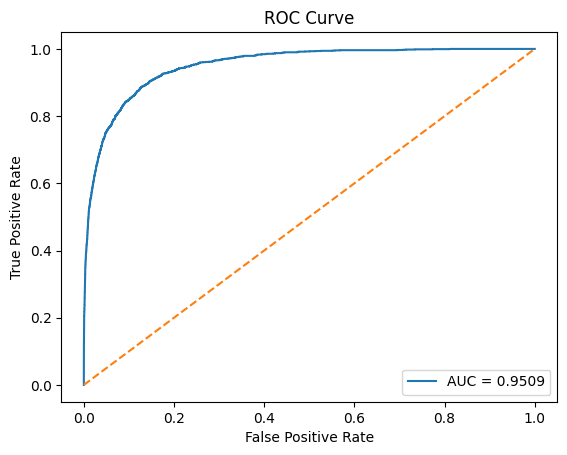

In [16]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

fpr, tpr, thresholds = roc_curve(labels, probs)

plt.figure()
plt.plot(fpr, tpr, label=f"AUC = {auc:.4f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

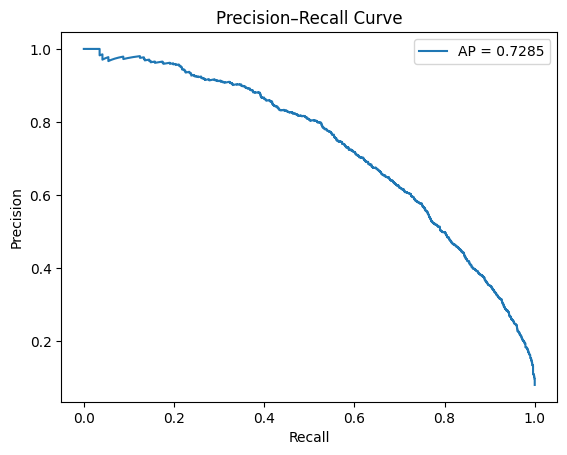

In [17]:
from sklearn.metrics import precision_recall_curve, average_precision_score

precision, recall, pr_thresholds = precision_recall_curve(labels, probs)
ap = average_precision_score(labels, probs)

plt.figure()
plt.plot(recall, precision, label=f"AP = {ap:.4f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve")
plt.legend()
plt.show()

In [18]:
print("===== FINAL EVALUATION METRICS =====")
print(f"Accuracy   : {accuracy:.4f}")
print(f"F1 Macro   : {f1:.4f}")
print(f"AUC-ROC    : {auc:.4f}")
print("\nConfusion Matrix:")
print(cm)

===== FINAL EVALUATION METRICS =====
Accuracy   : 0.9512
F1 Macro   : 0.8014
AUC-ROC    : 0.9509

Confusion Matrix:
[[18195   206]
 [  771   828]]


In [19]:
from sklearn.metrics import f1_score

thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]

for t in thresholds:
    preds_t = (probs >= t).astype(int)
    f1 = f1_score(labels, preds_t, average="macro")
    print(f"Threshold {t}: F1 Macro = {f1:.4f}")

Threshold 0.3: F1 Macro = 0.8095
Threshold 0.4: F1 Macro = 0.8071
Threshold 0.5: F1 Macro = 0.8014
Threshold 0.6: F1 Macro = 0.7936
Threshold 0.7: F1 Macro = 0.7828


Threshold Justification

The default threshold of 0.5 is commonly used, but it is not always optimal for this problem because the dataset is imbalanced and the cost of errors is not equal.

We evaluated F1-macro at different thresholds:

Threshold 0.3 → F1 = 0.8095
Threshold 0.4 → F1 = 0.8071
Threshold 0.5 → F1 = 0.8014
Threshold 0.6 → F1 = 0.7936
Threshold 0.7 → F1 = 0.7828

The highest F1 score is achieved at threshold 0.3.

Final Decision

We choose threshold = 0.3 for the rest of the assignment because it gives the best F1-macro score and improves the model’s ability to detect toxic comments.

Interpretation

Lowering the threshold increases recall, which means the model detects more toxic comments and reduces false negatives. This is important in content moderation because missing toxic content is more harmful than incorrectly flagging some non-toxic content.

Higher thresholds reduce false positives but increase false negatives, meaning more toxic comments are missed.

Conclusion

The selected threshold (0.3) reflects a safety-focused approach. The model is more aggressive in detecting harmful content, even if it slightly increases the number of incorrect flags on non-toxic comments.